# How Special Are Legendary Pokémon? What Makes a Pokemon Legendary, and Can We Predict It?

**Author:** Maxi Hase
**Course:** DCS 211, Fall 2026

**Dataset:** "The Complete Pokemon Dataset" by Rounak Banik, found on Kaggle (https://www.kaggle.com/datasets/rounakbanik/pokemon)

This notebook is part of my final project for DCS 211, and seeks to explore whether there is any relationship between certain stats of a Pokemon and them being legendary, as well as whether we can predict whether a given Pokemon will be legendary.

In [1]:
import pandas as pd
import numpy as np

import matplotlib.pyplot as plt
import seaborn as sns

from scipy import stats

from sklearn.model_selection import train_test_split, cross_val_score, cross_val_predict
from sklearn.preprocessing import StandardScaler
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import (accuracy_score, precision_score, recall_score,
                             f1_score, confusion_matrix, ConfusionMatrixDisplay)


## A. Data Collection and Exploration

In [2]:
df = pd.read_csv('data/pokemon.csv') # saving the CSV file as a dataframe
df.shape # 801 rows, 41 columns
df.head()

,abilities,against_bug,against_dark,against_dragon,against_electric,against_fairy,against_fight,against_fire,against_flying,against_ghost,...,percentage_male,pokedex_number,sp_attack,sp_defense,speed,type1,type2,weight_kg,generation,is_legendary
0,"['Overgrow', 'Chlorophyll']",1.0,1.0,1.0,0.5,0.5,0.5,2.0,2.0,1.0,...,88.1,1,65,65,45,grass,poison,6.9,1,0
1,"['Overgrow', 'Chlorophyll']",1.0,1.0,1.0,0.5,0.5,0.5,2.0,2.0,1.0,...,88.1,2,80,80,60,grass,poison,13.0,1,0
2,"['Overgrow', 'Chlorophyll']",1.0,1.0,1.0,0.5,0.5,0.5,2.0,2.0,1.0,...,88.1,3,122,120,80,grass,poison,100.0,1,0
3,"['Blaze', 'Solar Power']",0.5,1.0,1.0,1.0,0.5,1.0,0.5,1.0,1.0,...,88.1,4,60,50,65,fire,NaN,8.5,1,0
4,"['Blaze', 'Solar Power']",0.5,1.0,1.0,1.0,0.5,1.0,0.5,1.0,1.0,...,88.1,5,80,65,80,fire,NaN,19.0,1,0


In [3]:
df.dtypes

abilities                str
against_bug          float64
against_dark         float64
against_dragon       float64
against_electric     float64
against_fairy        float64
against_fight        float64
against_fire         float64
against_flying       float64
against_ghost        float64
against_grass        float64
against_ground       float64
against_ice          float64
against_normal       float64
against_poison       float64
against_psychic      float64
against_rock         float64
against_steel        float64
against_water        float64
attack                 int64
base_egg_steps         int64
base_happiness         int64
base_total             int64
capture_rate             str
classfication            str
defense                int64
experience_growth      int64
height_m             float64
hp                     int64
japanese_name            str
name                     str
percentage_male      float64
pokedex_number         int64
sp_attack              int64
sp_defense    

In [4]:
df.describe()

,against_bug,against_dark,against_dragon,against_electric,against_fairy,against_fight,against_fire,against_flying,against_ghost,against_grass,...,height_m,hp,percentage_male,pokedex_number,sp_attack,sp_defense,speed,weight_kg,generation,is_legendary
count,801.000000,801.000000,801.000000,801.000000,801.000000,801.000000,801.000000,801.000000,801.000000,801.000000,...,781.000000,801.000000,703.000000,801.000000,801.000000,801.000000,801.000000,781.000000,801.000000,801.000000
mean,0.996255,1.057116,0.968789,1.073970,1.068976,1.065543,1.135456,1.192884,0.985019,1.034020,...,1.163892,68.958801,55.155761,401.000000,71.305868,70.911361,66.334582,61.378105,3.690387,0.087391
std,0.597248,0.438142,0.353058,0.654962,0.522167,0.717251,0.691853,0.604488,0.558256,0.788896,...,1.080326,26.576015,20.261623,231.373075,32.353826,27.942501,28.907662,109.354766,1.930420,0.282583
min,0.250000,0.250000,0.000000,0.000000,0.250000,0.000000,0.250000,0.250000,0.000000,0.250000,...,0.100000,1.000000,0.000000,1.000000,10.000000,20.000000,5.000000,0.100000,1.000000,0.000000
25%,0.500000,1.000000,1.000000,0.500000,1.000000,0.500000,0.500000,1.000000,1.000000,0.500000,...,0.600000,50.000000,50.000000,201.000000,45.000000,50.000000,45.000000,9.000000,2.000000,0.000000
50%,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,...,1.000000,65.000000,50.000000,401.000000,65.000000,66.000000,65.000000,27.300000,4.000000,0.000000
75%,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,2.000000,1.000000,1.000000,1.000000,...,1.500000,80.000000,50.000000,601.000000,91.000000,90.000000,85.000000,64.800000,5.000000,0.000000
max,4.000000,4.000000,2.000000,4.000000,4.000000,4.000000,4.000000,4.000000,4.000000,4.000000,...,14.500000,255.000000,100.000000,801.000000,194.000000,230.000000,180.000000,999.900000,7.000000,1.000000


In [5]:
df['is_legendary'].value_counts() # 0: 731, 1: 70

is_legendary
0    731
1     70
Name: count, dtype: int64

In [6]:
# this first checks each entry in the dataframe for whether 
# it has a missing value (NaN), then sums up the number of missing values per column, and finally
# sorts the columns by how many missing values exist
df.isna().sum().sort_values(ascending=False) 

type2                384
percentage_male       98
weight_kg             20
height_m              20
name                   0
capture_rate           0
classfication          0
defense                0
experience_growth      0
hp                     0
japanese_name          0
abilities              0
base_happiness         0
pokedex_number         0
sp_attack              0
sp_defense             0
speed                  0
type1                  0
generation             0
base_total             0
base_egg_steps         0
against_bug            0
attack                 0
against_dark           0
against_dragon         0
against_electric       0
against_fairy          0
against_fight          0
against_fire           0
against_flying         0
against_ghost          0
against_grass          0
against_ground         0
against_ice            0
against_normal         0
against_poison         0
against_psychic        0
against_rock           0
against_steel          0
against_water          0


### Summary of Section A:

**Size and Structure:** The dataset contains 801 rows along with 41 features. Each row represents one Pokémon, and the features include abilities, stats (e.g. Attack, Defense, etc.), type, capture rate, among others.

**Data Types:** Most features are numerical values, as would be expected. There are also some expected string features, such as the name, or the type. However, there is one string feature that should be numerical: the capture rate. This suggests that there is at least one Pokémon with a non-numerical capture rate, which can either be a mistake in the dataset, or a quirk that a few Pokémon have. This will be investigated in Section B.

**Distribution of Legendary Pokémon:** There are 70 legendary Pokémon, and 731 non-legendary Pokémon. This makes about 8.7% of Pokémon in this Dataset legendary. This means two things for our context: For one, there is limited data to train on and to see patterns in, and secondly, the data is heavily skewed towards non-legendary Pokémon. If a model simply guessed that every given Pokémon is not legendary, it would be right 91.3% of the time, so this is the baseline that this prediction model would have to beat.

**Missing values:** There are four features with missing entries for some Pokémon. The two most frequent are to be expected: most notably, 384 Pokémon are missing an entry for a second type. This is most likely because these Pokémon only have one type, so there is no second type to list. For example, while Venusaur is of Type Grass and Poison, Turtoise only has Type Water. Additionally, there are 98 Pokémon without a percentage of male Pokémon (to female), which is also not quite as surprising, because some Pokémon don't have a gender, such as Porygon. 
The other two features are more curious, however. Namely, there are 20 missing entries both for height and weight. These will need to be investigated in the next section.

## B. Data Cleansing and Preprocessing

In [7]:
# creating a working copy of the dataframe
df_clean = df.copy()

In [8]:
# checking any duplicate entries
print(df_clean.duplicated().sum()) # number of identical rows: 0
print(df_clean['name'].duplicated().sum()) # number of identical names: 0

0
0


In [9]:
# inspecting the invalid values for the capture rate
converted = pd.to_numeric(df_clean['capture_rate'], errors='coerce') # turn entries into numerical values
df_clean.loc[converted.isna(), ['name', 'capture_rate']] # show all names and capture rates for Pokémon where conversion failed

,name,capture_rate
773,Minior,30 (Meteorite)255 (Core)


In [10]:
# the meteorite form is the default form, so we will use that form
# replacing the entry with capture rate 30
df_clean.loc[df_clean['name']=='Minior', 'capture_rate'] = '30'
#turning all entries into numerical entries
df_clean['capture_rate'] = pd.to_numeric(df_clean['capture_rate'])

# print data type to check
print(df_clean['capture_rate'].dtype) # int64

int64


In [11]:
print(df_clean.loc[df_clean['name']=='Minior',['name','capture_rate']])

       name  capture_rate
773  Minior            30


In [12]:
# checking which Pokémon have missing height entries
df_clean.loc[df_clean['height_m'].isna(), ['name', 'generation', 'is_legendary']]

,name,generation,is_legendary
18,Rattata,1,0
19,Raticate,1,0
25,Raichu,1,0
26,Sandshrew,1,0
27,Sandslash,1,0
36,Vulpix,1,0
37,Ninetales,1,0
49,Diglett,1,0
50,Dugtrio,1,0
51,Meowth,1,0


In [13]:
# checking which Pokémon have missing weight entries
df_clean.loc[df_clean['weight_kg'].isna(), ['name', 'generation', 'is_legendary']]
# Note that these are the same Pokémon that are missing height entries
# all of these Pokémon have alternate forms

,name,generation,is_legendary
18,Rattata,1,0
19,Raticate,1,0
25,Raichu,1,0
26,Sandshrew,1,0
27,Sandslash,1,0
36,Vulpix,1,0
37,Ninetales,1,0
49,Diglett,1,0
50,Dugtrio,1,0
51,Meowth,1,0


In [14]:
#checking if there are other Pokémon that use different forms
df_clean.loc[df_clean['type1']==df_clean['type2'],['name','type1','type2']]
# all of these Pokémon have alternate forms, and here again their types get confused. Perhaps this is the case for all Pokémon with
# alternate forms?

,name,type1,type2
25,Raichu,electric,electric
49,Diglett,ground,ground
50,Dugtrio,ground,ground
87,Grimer,poison,poison
88,Muk,poison,poison
491,Shaymin,grass,grass
554,Darmanitan,fire,fire


In [15]:
# checking stats for some Mega-Pokemon, as these have inflated stats, and would most affect the results:
print(df_clean.loc[df_clean['name']=='Charizard',['base_total']])
print(df_clean.loc[df_clean['name']=='Tyranitar',['base_total']])
print(df_clean.loc[df_clean['name']=='Rayquaza',['base_total']])


   base_total
5         634
     base_total
247         700
     base_total
383         780


### Alternate Forms in the Data

Investigating the discrepancies further and trying to fix them has revealed some bigger issues. At first, it seemed that there was a problem only with Alolan form Pokémon that were missing entries for their height and weight. Using the Alolan forms instead of the default Kantonian forms does not affect the stats in a noticeable manner, so I decided to simply use those forms at first.

Further investigations revealed, however, that many Pokémon with alternate forms, use the alternate stats and entries, with some mixed types. While the mixed types would most likely not affect the results by a lot, some of the alternate stats massively impact the analysis. Most notably, Pokémon with mega evolutions receive a total stat boost of 100, which pushes many non-legendary Pokémon to be stronger than legendary Pokémon. This would most likely lead to a lot of non-legendary Pokémon to be identified as legendary. This is a big discovery, and needs fixing.

To address this issue, I will use a more reliable API that lists all default stats. In a different script, I will convert this API to a CSV file, that I will use to finish cleaning up the data here. Here is the link to the home page of the API: https://pokeapi.co/

The source is PokéAPI, with this documentation: https://pokeapi.co/v2/openapi/operations/pokemon_retrieve
The whole address for each Pokémon is https://pokeapi.co/api/v2/pokemon/{pokedex_number}, where {pokedex_number} is to be replaced with a Pokémon's pokedex number. It then returns a JSON object describing one Pokémon's default form. I will focus on stats, types, height and weight, as the other entries are not relevant to this data analysis.

In [16]:
# loading and inspecting the API dataset
api_df = pd.read_csv('data/pokeapi.csv')
print(api_df.shape)
print(api_df.isna().sum())

api_df.head()

(801, 12)
pokedex_number      0
api_name            0
hp                  0
attack              0
defense             0
sp_attack           0
sp_defense          0
speed               0
height_m            0
weight_kg           0
type2             400
type1               0
dtype: int64


,pokedex_number,api_name,hp,attack,defense,sp_attack,sp_defense,speed,height_m,weight_kg,type2,type1
0,1,bulbasaur,45,49,49,65,65,45,0.7,6.9,poison,grass
1,2,ivysaur,60,62,63,80,80,60,1.0,13.0,poison,grass
2,3,venusaur,80,82,83,100,100,80,2.0,100.0,poison,grass
3,4,charmander,39,52,43,60,50,65,0.6,8.5,NaN,fire
4,5,charmeleon,58,64,58,80,65,80,1.1,19.0,NaN,fire


In [17]:
# checking if all pokedex numbers line up
print((df_clean['pokedex_number']==api_df['pokedex_number']).all()) # all() is True only if all pokedex entries line up
# investigating which Pokémon have stat changes or type changes
any_changed = ((abs(df_clean['hp'] - api_df['hp'])
            + abs(df_clean['attack']-api_df['attack'])
            + abs(df_clean['defense']-api_df['defense'])
            + abs(df_clean['sp_attack']-api_df['sp_attack'])
            + abs(df_clean['sp_defense']-api_df['sp_defense'])
            + abs(df_clean['speed']-api_df['speed']) != 0)
            |(df_clean['type1'] != api_df['type1']) | (df_clean['type2'].fillna('none') != api_df['type2'].fillna('none')))
# making sure all columns are shown after this
pd.set_option('display.max_rows', 100)
print(any_changed.sum())
df_clean.loc[any_changed, ['name', 'hp', 'attack', 'defense', 'sp_attack',
                           'sp_defense', 'speed', 'type1', 'type2']]

True
85


,name,hp,attack,defense,sp_attack,sp_defense,speed,type1,type2
2,Venusaur,80,100,123,122,120,80,grass,poison
5,Charizard,78,104,78,159,115,100,fire,flying
8,Blastoise,79,103,120,135,115,78,water,NaN
14,Beedrill,65,150,40,15,80,145,bug,poison
17,Pidgeot,83,80,80,135,80,121,normal,flying
18,Rattata,30,56,35,25,35,72,normal,dark
19,Raticate,75,71,70,40,80,77,normal,dark
25,Raichu,60,85,50,95,85,110,electric,electric
26,Sandshrew,50,75,90,10,35,40,ground,ice
27,Sandslash,75,100,120,25,65,65,ground,ice


In [18]:
# all the above Pokémon have some alternate form, except for Cresselia
# creating a feature of the sum of stats for the API dataframe
api_df['base_total'] = api_df['hp'] + api_df['attack'] + api_df['defense'] + api_df['sp_attack'] + api_df['sp_defense'] + api_df['speed']

In [19]:
# checking which Pokémon have no stat changes, but changes otherwise (e.g. types)
total_unchanged = df_clean['base_total'] == api_df['base_total']
df_clean.loc[any_changed & total_unchanged, ['name', 'type1', 'type2']]

,name,type1,type2
18,Rattata,normal,dark
19,Raticate,normal,dark
25,Raichu,electric,electric
26,Sandshrew,ground,ice
27,Sandslash,ground,ice
36,Vulpix,fire,ice
37,Ninetales,fire,ice
49,Diglett,ground,ground
50,Dugtrio,ground,ground
51,Meowth,normal,dark


In [20]:
# Coming back to Cresselia, Cresselia's stats were changed in a later game (https://bulbapedia.bulbagarden.net/wiki/Cresselia_(Pok%C3%A9mon))
# Instead, I will use the original dataset's stats for Cresselia

stat_columns = ['base_total', 'hp', 'attack', 'defense', 'sp_attack', 'sp_defense', 'speed']
api_df.loc[api_df['api_name'] == 'cresselia', stat_columns] = df.loc[df['name'] == 'Cresselia', stat_columns].values
print(api_df.loc[api_df['api_name']=='cresselia', ['base_total']])

     base_total
487         600


In [21]:
# finally, I will replace all the original dataset's stat columns with the API stats
replace_columns = ['hp', 'attack', 'defense', 'sp_attack', 'sp_defense', 'speed', 
                   'type1', 'type2', 'height_m', 'weight_kg', 'base_total']
df_clean[replace_columns] = api_df[replace_columns]

In [22]:
# verifying
print(df_clean[['height_m', 'weight_kg']].isna().sum()) # 0 expected
print((df_clean['type1']==df_clean['type2']).sum()) # 0 expected
df_clean.loc[df_clean['name'].isin(['Charizard', 'Tyranitar', 'Cresselia']), ['name', 'base_total']] #small sample to check

height_m     0
weight_kg    0
dtype: int64
0


,name,base_total
5,Charizard,534
247,Tyranitar,600
487,Cresselia,600


The above verification shows that the stats, types, and height and weight follow the default forms now, so we can move on to the 'percentage_male' feature.

In [23]:
# next, I will investigate and clean the percentage_male feature
print(df_clean['percentage_male'].value_counts())
print(df_clean['percentage_male'].value_counts().sum())

percentage_male
50.0     501
88.1     111
0.0       27
24.6      24
100.0     19
75.4      19
11.2       2
Name: count, dtype: int64
703


In [24]:
# The above test shows there are 98 (801-703) missing entries
df_clean.loc[df_clean['percentage_male'].isna(), ['name']]

,name
80,Magnemite
81,Magneton
99,Voltorb
100,Electrode
119,Staryu
120,Starmie
131,Ditto
136,Porygon
143,Articuno
144,Zapdos


In [25]:
# all of the above Pokémon are genderless, so this explains the missing values
# I will now create a new column that tracks whether a Pokémon is genderless, with 1: True, 0: False
df_clean['is_genderless'] = df_clean['percentage_male'].isna().astype(int)
print(df_clean['is_genderless'].sum()) # checking; should sum up to 98

98


In [26]:
# To work with the types, I will create columns corresponding to each type, with 1: pokemon is of this type, and 0: otherwise

types_list = df_clean['type1'].unique()
for t in types_list:
    df_clean[f'type_{t}'] = ((df_clean['type1'] == t) | (df_clean['type2'] == t)).astype(int)

#... along with a check
print(len(types_list)) # should be 18
print(df_clean.loc[df_clean['name']=='Charizard', ['type_fire', 'type_flying', 'type_grass']]) # should be 1 1 0


18
   type_fire  type_flying  type_grass
5          1            1           0


In [27]:
# Lastly, save the dataframe as a CSV file
df_clean.to_csv('data/pokemon_clean.csv', index=False)

### Summary of Section B

**Duplicates:** There were no duplicate rows or Pokémon, so there was no work to be done here.

**Invalid values:** There was one invalid value for the capture rates, which was caused by the Pokémon Minior. Minior has two different forms (default and core), which have different capture rates. The dataset listed both, with the forms specified, resulting in a string value as opposed to a simple integer. I chose the capture rate of the default form, and this will be the default choice for other choices in this section, too.

**Alternate forms:** This was by far the main finding in this dataset so far. After investigating some of the missing values for height and weight, I found out that all of the Pokémon with missing heights and weights (20 in total) were Pokémon with alternate forms, most of them so called Alola forms. These Pokémon also had discrepancies in their types, which led me to further investigate other Pokémon with alternate forms, and it turns out that many Pokémon (85, making up 10.6% of the entire dataset) with alternate forms ended up using the alternate form entries, or mixing entries between the different forms. Most notably, Pokémon with Mega Evolutions used the stats of the Mega Evolution. This gives these Pokémon significant stat boosts, making some non-legendary Pokémon stronger than legendary ones, and heavily distorts the data.
To fix this, I used the more accurate PokéAPI to create a second CSV file with the default form entries, and replaced the relevant columns with those of this new CSV file, since it only uses the default forms. The only exception here is Cresselia, which received a slight stat change in a recent generation (ninth generation) putting its total stats down to 580 instead of 600. Because all other Pokémon use their 7th generation entries, I decided to keep Cresselia's old entries, too.

**Missing values:** There were multiple missing height and weight entries, which were fixed as described above. For the percentage_male feature, a missing value indicated that a Pokémon is genderless. In total, there were 98 genderless Pokémon, many of which are legendary, and I left these entries empty, and instead created a new feature (is_genderless) that tracks whether a Pokémon is genderless or not. Lastly, the missing entries for type2 included all the Pokémon that only have a single type (400 of them); these missing entries were left empty. 

**Encoding:** Because a later kNN analysis needs numbers, I created a column for every type that tracks whether a given Pokémon has a given type (1) or not (0). 

**Scaling:** Scaling is postponed to section F, because otherwise it would affect the testing data.

**Result:** The resulting cleaned dataset is saved as pokemon_clean.csv in the data directory.

## C. Exploratory Data Analysis

In this section, I will try to answer the following questions:

1. What percentage of Pokémon are legendary?
2. Do legendaries have higher stats, and which individual stats differ the most?
3. Are legendaries harder to catch, and are they bigger/heavier?
4. Is legendary status in any way related to generation?
5. Are certain types more common among legendaries?
6. How strongly is being genderless associated with being legendary?
7. Which attributes are most strongly associated with legendary status?
8. Which 'near-legendary' Pokémon have legendary-like stats, but are non-legendary?

### C.1 What percentage of Pokémon are legendary?

In [28]:
# checking how many Pokémon are legendary
print(df_clean['is_legendary'].sum())

70


In [29]:
# Checking what percentage this accounts for
df_clean['is_legendary'].value_counts(normalize = True) * 100

is_legendary
0    91.260924
1     8.739076
Name: proportion, dtype: float64

In total, 70 Pokémon are legendary, and this makes up about 8.7% of the dataset. Conversely, this makes 91.3% non-legendary, so simply guessing that a Pokémon is non-legendary all the time would be correct 91.3% of the time. This means that, for one, this is the baseline for any prediction models, but also that we will need to consider other ways to measure performance of our predictions, such as precision and recall. Additionally, because there are so few legendary Pokémon, any 'outlying' legendaries could have a noticeable effect on the average.

### C.2 Do legendaries have higher stats, and which individual stats differ the most?

In [30]:
# comparing the total stats
df_clean.groupby('is_legendary')['base_total'].agg(['mean','median','min', 'max']) # agg calculates multiples statistics at once

,mean,median,min,max
is_legendary,,,,
0,403.566347,413.0,175,670
1,602.000000,600.0,200,720


In [31]:
# counting how many have exactly 600
is_600_legendary =(df_clean['is_legendary']==1) & (df_clean['base_total']==600)
print(is_600_legendary.sum())
df_clean.loc[is_600_legendary, ['name']]

21


,name
150,Mew
250,Celebi
379,Latias
380,Latios
384,Jirachi
385,Deoxys
484,Heatran
487,Cresselia
489,Manaphy
490,Darkrai


In [32]:
# checking which legendary Pokémon have less than 600
weak_legendary = df_clean.loc[((df_clean['is_legendary']==1)) & (df_clean['base_total'] < 600), ['name', 'base_total']]
print(weak_legendary)
# checkin how many legendary Pokémon have less than 600
print(len(weak_legendary))

           name  base_total
143    Articuno         580
144      Zapdos         580
145     Moltres         580
242      Raikou         580
243       Entei         580
244     Suicune         580
376    Regirock         580
377      Regice         580
378   Registeel         580
479        Uxie         580
480     Mesprit         580
481       Azelf         580
637    Cobalion         580
638   Terrakion         580
639    Virizion         580
640    Tornadus         580
641   Thundurus         580
646      Keldeo         580
784   Tapu Koko         570
785   Tapu Lele         570
786   Tapu Bulu         570
787   Tapu Fini         570
788      Cosmog         200
789     Cosmoem         400
792    Nihilego         570
793    Buzzwole         570
794   Pheromosa         570
795   Xurkitree         570
796  Celesteela         570
797     Kartana         570
798    Guzzlord         570
31


In [33]:
# comparing the individual stats
stat_columns = ['hp', 'attack', 'defense', 'sp_attack', 'sp_defense', 'speed']
df_clean.groupby('is_legendary')[stat_columns].mean()

,hp,attack,defense,sp_attack,sp_defense,speed
is_legendary,,,,,,
0,66.314637,73.091655,68.938440,65.370725,66.871409,62.979480
1,93.885714,104.728571,98.857143,109.914286,101.685714,92.928571


As expected, legendaries have, on average, much higher stats. The sum of the stats is on average about 200 higher (602 vs 403), and this is similar for the median (600 vs 413, so about 50% higher). The biggest difference was in the special attack, where the mean for legendaries is about 45 (110 vs 65) higher than for non-legendaries, while the means for the other stats are about 30 to 35 higher than those for non-legendaries. Additionally, while the highest (mean) stat for non-legendaries is attack (73), the highest (mean) stat for legendaries is special attack (110). While I expected attack to be the highest stat for non-legendaries, it's surprising to see special attack as the highest (mean) score for legendary Pokémon.

### C.3 Are legendaries harder to catch, and are they bigger/heavier?

In [34]:
# comparing capture rates, height, and weight
df_clean.groupby('is_legendary')[['capture_rate', 'height_m', 'weight_kg']].agg(['mean', 'median'])

capture_rate         height_m          weight_kg       
                     mean median      mean median        mean median
is_legendary                                                        
0              106.402189   75.0  1.048564    0.9   47.897674   25.0
1               17.985714    3.0  2.255714    1.8  196.922857  110.0

In [35]:
# checking which legendaries are unusually easy to catch
legendaries = df_clean[df_clean['is_legendary'] == 1]
legendaries.sort_values('capture_rate', ascending = False)[['name', 'capture_rate']].head(10)

,name,capture_rate
797,Kartana,255
794,Pheromosa,255
383,Rayquaza,45
250,Celebi,45
491,Shaymin,45
788,Cosmog,45
789,Cosmoem,45
790,Solgaleo,45
716,Yveltal,45
792,Nihilego,45


In [36]:
# checking the smallest legendaries
legendaries.sort_values('height_m')[['name', 'height_m', 'weight_kg']].head(10)

,name,height_m,weight_kg
789,Cosmoem,0.1,999.9
788,Cosmog,0.2,0.1
491,Shaymin,0.2,2.1
797,Kartana,0.3,0.1
489,Manaphy,0.3,1.4
481,Azelf,0.3,0.3
480,Mesprit,0.3,0.3
479,Uxie,0.3,0.3
384,Jirachi,0.3,1.1
493,Victini,0.4,4.0


As expected, legendaries are much harder to catch, with an average capture rate of 18 vs the non-legendaries' 106, where a lower capture rate indicates that a Pokémon is harder to catch. However, the mean deviates a lot from the median: the median for non-legendaries is 75, while the median for legendaries is 3. Investigating some of the highest capture rates for legendaries, we can explain the high mean: Two so-called Ultra Beasts have a capture rate of 255, because they are typically caught with a special ball, so the designers changed the capture rate for them. Because there aren't many legendaries to begin with, this has a noticeable impact on the mean, but doesn't change the median. A capture rate of 3 is a very common capture rate for legendary Pokémon, so it's not surprising to see this as the median. The mean and median for the height and weight are expectedly larger for legendaries than for non-legendaries, with legendaries having roughly double the height (mean 2.2 vs 1.0, median 1.8 vs 0.9), and four times the weight of non-legendaries (mean 197 vs 48, median 110 vs 25). I expected the difference in height to be more pronounced, but after investigating some of the smaller legendary Pokémon, this finding makes sense: many mythical Pokémon, that also count as legendary, are typically small (and weigh less, too), and this drags down the averages. Something that is noticeable here is that the definition of 'legendary' matters. This dataset groups together Ultra Beasts, mythical Pokémon, and 'standard' legendary Pokémon, that typically have different defining characteristics.

### C.4 Is legendary status in any way related to generation?

In [37]:
# checking how many legendaries each generation has
pd.crosstab(df_clean['generation'], df_clean['is_legendary'])

is_legendary,0,1
generation,,
1,146,5
2,94,6
3,125,10
4,94,13
5,143,13
6,66,6
7,63,17


In [38]:
# checking the share of legendaries in each generation
df_clean.groupby('generation')['is_legendary'].mean() * 100

generation
1     3.311258
2     6.000000
3     7.407407
4    12.149533
5     8.333333
6     8.333333
7    21.250000
Name: is_legendary, dtype: float64

In [39]:
# checking Gen 7's unusually high share of legendaries

df_clean.loc[(df_clean['generation'] == 7) & (df_clean['is_legendary'] == 1), ['name', 'base_total']]

,name,base_total
784,Tapu Koko,570
785,Tapu Lele,570
786,Tapu Bulu,570
787,Tapu Fini,570
788,Cosmog,200
789,Cosmoem,400
790,Solgaleo,680
791,Lunala,680
792,Nihilego,570
793,Buzzwole,570


In [40]:
# checking Gen 4's unusually high share of legendaries

df_clean.loc[(df_clean['generation'] == 4) & (df_clean['is_legendary'] == 1), ['name', 'base_total']]

,name,base_total
479,Uxie,580
480,Mesprit,580
481,Azelf,580
482,Dialga,680
483,Palkia,680
484,Heatran,600
485,Regigigas,670
486,Giratina,680
487,Cresselia,600
489,Manaphy,600


I initially expected there to be a slight increase in share of legendaries over the generations, and while the share of legendaries did increase, the increase is 1. not steady, and 2. way more pronounced than I expected. At first, legendaries made up about 3% of Generation 1 Pokémon; this share was then doubled to 6% in Generation 2, and Generation 3, 5 and 6 have a share of 7, 8 and 8%, respectively. There are two outliers, however: In Generation 4, legendary Pokémon make up about 12% of Pokémon. This can be traced back to the fact that the fourth Generation was a lot about mythology, including two legendary trios and four mythical Pokémon. Even more extreme, however, was the jump in Generation 7, with 21% of Pokémon being legendary, which in absolute terms are 17 Pokémon (vs 63 non-legendaries). This high number can be traced back to the 7 Ultra Beasts that are counted as legendary here (without these, legendaries would make up about 13%, which is closer to Generation 4), but also the four Tapu Pokémon and evolution chain of Cosmog, Cosmoem, and Solgaleo/Lunala, which is rather unusual for legendary Pokémon.
Note, however, that some Pokémon that are typically considered legendary are not listed here: In Generation 4, Phione is missing, and in Generation 7, Type: Null and Silvally. These three are falsely labeled as non-legendary.

### C.5 Are certain types more common among legendaries?

In [41]:
# checking what share of legendaries has each type, compared to the share of non-legendaries

type_columns = [f'type_{t}' for t in types_list] # using the list created before
type_shares = df_clean.groupby('is_legendary')[type_columns].mean().T * 100 # T transposes the output and makes it easier to read
type_shares.sort_values(1, ascending = False)

is_legendary,0,1
type_psychic,8.344733,30.000000
type_flying,11.901505,15.714286
type_dragon,4.514364,15.714286
type_steel,4.924761,14.285714
type_fairy,5.471956,10.000000
type_water,16.963064,10.000000
type_fire,7.660739,10.000000
type_fighting,6.429549,8.571429
type_electric,5.608755,8.571429
type_grass,12.585499,7.142857


In [42]:
# directly comparing which types are under- and overrepresented, by looking at the differences
type_shares['difference'] = type_shares[1] - type_shares[0]
type_shares.sort_values('difference', ascending = False)

is_legendary,0,1,difference
type_psychic,8.344733,30.000000,21.655267
type_dragon,4.514364,15.714286,11.199922
type_steel,4.924761,14.285714,9.360954
type_fairy,5.471956,10.000000,4.528044
type_flying,11.901505,15.714286,3.812781
type_electric,5.608755,8.571429,2.962673
type_fire,7.660739,10.000000,2.339261
type_fighting,6.429549,8.571429,2.141880
type_ice,4.240766,4.285714,0.044948
type_ghost,5.198358,4.285714,-0.912644


I expected dragon and fairy to be fairly common and overrepresented among legendaries, while normal and bug would be less common, and underrepresented among legendaries. My expectations weren't wrong, but by far the most common type among legendaries was Psychic, with 30% of legendary Pokémon vs only 8% among non-legendaries; this could be due to the fact that many legendary Pokémon are supposed to be 'mysterious', and Psychic represents exactly that. This is followed by Flying with 16% vs 12%, and Dragon with 16% vs 5%. In terms of being more common among legendaries than non-legendaries, Psychic is followed by Dragon, then Steel with 14% vs 5%, and Fairy with 10% vs 5.5%.
On the bottom, Poison is by far the least represented, with only 1.4% of legendaries having Type Poison. This is followed by Ground, Ghost, Ice, Normal, Dark and Bug, each with about 4%. If we compare this to non-legendaries, then the least represented type is actually Normal, with 4% among legendaries, and 15% among non-legendaries, followed by Poison with 1.4% vs 8.6%. Bug is, as expected, also fairly underrepresented, with 4% among legendaries vs 10% among non-legendaries. Note that, among legendary Pokémon, 1.4% represents one Pokémon, so if we compare 1.4% and 4.2%, we're talking about 1 Pokémon and 3 Pokémon, so the absolute difference isn't as impressive as it might seem at first.

### C.6 How strongly is being genderless associated with being legendary?

In [43]:
# checking how many legendaries and non-legendaries are genderless
pd.crosstab(df_clean['is_genderless'], df_clean['is_legendary'])

is_legendary,0,1
is_genderless,,
0,696,7
1,35,63


In [44]:
# putting it into relative terms
df_clean.groupby('is_legendary')['is_genderless'].mean() * 100

is_legendary
0     4.787962
1    90.000000
Name: is_genderless, dtype: float64

The connection between being genderless and being legendary is even stronger than I initially assumed (I predicted 80% and 10% for legendaries and non-legendaries, respectively), with 90% of legendary Pokémon being genderless, compared to only 4.8% of non-legendary Pokémon. This makes being genderless a very strong indicator for whether a Pokémon is legendary, which can be used for our prediction model later on. However, it's not a perfect indicator: looking at the reverse, only about 64% of genderless Pokémon are legendary, so we cannot solely use this as an indicator, especially because there are still 7 gendered legendaries (Latias, Latios, Heatran, Cresselia, and the three Forces of Nature), and many non-legendaries that are genderless (36% of the genderless Pokémon).

### C.7 Which attributes are most strongly associated with legendary status?

In [45]:
# investigating the correlation between mutliple attributes at once
attributes = ['base_total', 'hp', 'attack', 'defense', 'sp_attack', 'sp_defense', 'speed',
              'capture_rate', 'height_m', 'weight_kg', 'is_genderless', 'generation'] #creating a list of the attributes we want to consider
df_clean[attributes + ['is_legendary']].corr()['is_legendary'].sort_values(ascending = False) #creating a table of all correlations, 
# then only looking at the is_legendary column

is_legendary     1.000000
is_genderless    0.734375
base_total       0.506324
sp_attack        0.429596
weight_kg        0.387821
sp_defense       0.360041
height_m         0.318782
speed            0.308259
attack           0.303491
hp               0.298480
defense          0.287655
generation       0.139029
capture_rate    -0.327677
Name: is_legendary, dtype: float64

In [46]:
correlations = df_clean[attributes + ['is_legendary']].corr()['is_legendary'].drop('is_legendary') #creating a table of all correlations, 
#then only looking at the is_legendary column
#looking at the absolute values of correlations
correlations.abs().sort_values(ascending=False)

is_genderless    0.734375
base_total       0.506324
sp_attack        0.429596
weight_kg        0.387821
sp_defense       0.360041
capture_rate     0.327677
height_m         0.318782
speed            0.308259
attack           0.303491
hp               0.298480
defense          0.287655
generation       0.139029
Name: is_legendary, dtype: float64

As expected, being genderless has the highest association to being legendary, with an absolute association value of 0.73, followed by base_total with 0.51, sp_attack with 0.43, and weight with 0.39. Capture rate is surprisingly in the middle field, with 0.33. This shows that the sum of stats is much more of an indicator than any individual stat, although special attack does have a high correlation, as we had seen earlier as well. The generation his the least associated with being legendary, at only 0.14. For the capture rate, note that it's the only attribute negatively associated, with its value actually being -0.33, which means that a lower capture_rate is more associated with legendary status, which makes sense from our earlier findings.
Note, however, that correlation does not imply causation, and this is specifically about linear association.

### C.8 Which 'near-legendary' Pokémon have legendary-like stats, but are non-legendary?

In [47]:
is_non_legendary = df_clean['is_legendary'] == 0
#defining near-legendary Pokémon as Pokémon with a base_total of greater than or equal to 600
near_legendary = df_clean.loc[is_non_legendary & (df_clean['base_total'] >= 600),
                              ['name', 'base_total', 'generation', 'is_genderless']]
# sorting the near-legendaries by base_total
near_legendary.sort_values('base_total', ascending = False)

,name,base_total,generation,is_genderless
288,Slaking,670,3,0
148,Dragonite,600,1,0
247,Tyranitar,600,2,0
372,Salamence,600,3,0
375,Metagross,600,3,1
444,Garchomp,600,4,0
634,Hydreigon,600,5,0
705,Goodra,600,6,0
783,Kommo-o,600,7,0


Here, I defined 'near-legendary' Pokémon as Pokémon with a base total of 600 or above. There are actually fewer non-legendary Pokémon with a base_total of 600 and above than I expected (I expected about 15), with 8 Pokémon having a base total of exactly 600, and Slaking topping the list with a base total of 670 (which I did not expect). This list can be easily explained: Apart from Slaking, all Pokémon in this list are so-called pseudo-legendaries. Each generation, the developers include one non-legendary Pokémon with a base total of 600, with the only exception being the third generation, which included 2 of these Pokémon. The outlier here is Slaking, which has the highest base total of 670, which is due to its ability, that only allows it to move every second turn, effectively weakening it, so the high stats are somewhat deceiving. Also note that the only genderless Pokémon here is Metagross, so it's very likely that Metagross will later on be falsely predicted as legendary. The other pseudo-legendaries are also likely to be confused, because 600 is a very common base total for legendary Pokémon

### Summary of Section C

**Main findings**
1. **Imbalance:** 8.7% of Pokémon are legendary, so any model that simply predicts non-legendary for all Pokémon will be right 91.3% of the time. This makes 91.3% the baseline for any prediction model that we want to build. Additionally, this shows that precision/recall are also important viewpoints to consider for evaluating any model's performance.
2. **Stats:** The mean for the total stats of legendary Pokémon is 602, compared to the non-legendaries' 403, making legendaries' stats about 50% higher. This is similar for the median, since low and high outliers balance. Looking at individual stats, special attack differs most, with 110 being the mean for legendaries, versus 65 for non-legendaries. The other stats are typically 30 to 35 higher for legendary Pokémon.
3. **Catchability and size:** The median for the capture rate of legendary Pokémon is 3, compared to 75 for non-legendaries. The mean gets brought up by some outliers such as Ultra Beasts that have a capture rate of 255, as well as non-legendary Pokémon with a capture rate of 255, bringing up the means to 18 and 106. Note that a lower capture rate means that a Pokémon is harder to catch.
Also, legendary Pokémon are definitely heavier (mean 197 vs 48) and taller (mean 2.2 vs 1.0), though small and lightweight mythical Pokémon pull the means down.
4. **Generations:** Overall, the share of legendary Pokémon rises from 3% in Generation 1, to 6%, 7%, and 8% in the following Generations. There are two outliers, however, those being Generation 4 (about 12%) and Generation 7 with 21%. Generation 4 includes two trios, as well as 4 mythical Pokémon, while Generation 7 is mainly inflated by 7 Ultra Beasts, that are counted as legendary in this dataset.
5. **Types:** Psychic is by far the most over-represented, with 30% of legendary Pokémon having type Psychic, compared to 8% of non-legendaries. Psychic is followed by Dragon, Steel and Fairy, though these sit at 10% to 15%.
Normal and Poison are the most under-represented types, with 4.3% of legendary Pokémon having type Normal compared to 14.5% of non-legendaries, and 1.4% vs 8.6% for Poison.
6. **Gender:** 90% of legendaries are genderless, compared to only 4.8% of non-legendaries. Conversely, only 64% of genderless Pokémon are legendary.
7. **Strongest associations:** The ranking of associations is is_genderless (0.73), base_total (0.51), sp_attack (0.43), weight_kg (0.39), sp_defense (0.36), capture_rate (-0.33), height_m (0.32), the other stats at about 0.3, and generation at 0.14
8. **Near-legendaries:** There are 8 pseudo-legendaries with a base total of 600, plus Slaking with a base total of 670. Metagross is the only genderless of these.

**Overall picture**
Something that showed up in several of these analyses is the fact that being legendary is actually a mixed category of mythical Pokémon, Ultra Beasts, and 'standard' legendary Pokémon, which distorts some of the common features of legendary Pokémon, and mixes the features of these different categories.
Additionally, there is no single trait that perfectly corresponds to being legendary. There are genderless non-legendaries, just like there are gendered legendaries. Legendary Pokémon have high stats, but so do pseudo-legendaries. 
This could pose some difficulties in section F when trying to predict pseudo-legendaries or mythical Pokémon, as these might be falsely classified, especially Metagross.

## D. Data Visualization

This section visualizes some of the main findings in section C, each followed by a short interpretation. All figures are saved in the figures directory.

1. Legendary vs. non-legendary counts (C.1)
2. Total stats by legendary status (C.2)
3. Individual stats by legendary status (C.2)
4. Distribution of total stats for both groups, overlaid (C.2, C.8)
5. Percentage of legendary Pokémon per generation (C.4)
6. Type differences between legendary and non-legendary Pokémon (C.5)
7. Correlation heatmap of different attributes (C.7)

### D.1 Legendary vs non-legendary counts

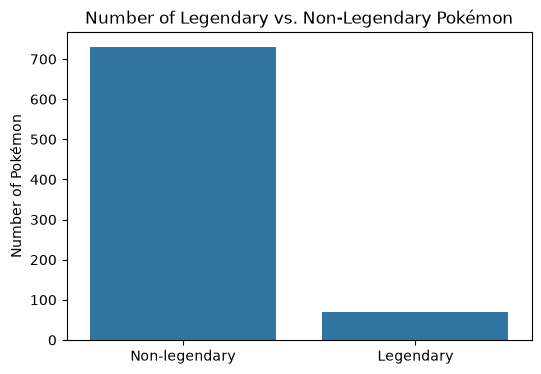

In [48]:
# creating a plot for legendary vs. non-legendary counts
plt.figure(figsize = (6, 4)) # creates the canvas
sns.countplot(data = df_clean, x = 'is_legendary') # draws the bar chart
plt.xticks([0, 1], ['Non-legendary', 'Legendary']) # replaces the labels under the bars (otherwise 0 and 1)
plt.title("Number of Legendary vs. Non-Legendary Pokémon")
plt.xlabel("") # sets empty x label
plt.ylabel("Number of Pokémon")
plt.savefig('figures/01_legendary_count.png', dpi = 150, bbox_inches = 'tight') # saves the figure to the figures directory
plt.show()

This figure visualizes how few legendary Pokémon there are in comparison to non-legendary Pokémon: only 70 of 801 Pokémon are legendary, so the legendary bar makes up less than a tenth of the non-legendary bar. This, as has been noted before, affects the data analysis in that even single outliers can affect the mean for legendaries, and precision/recall becomes much more indicative for our model's performance.

### D.2 Total stats by legendary status

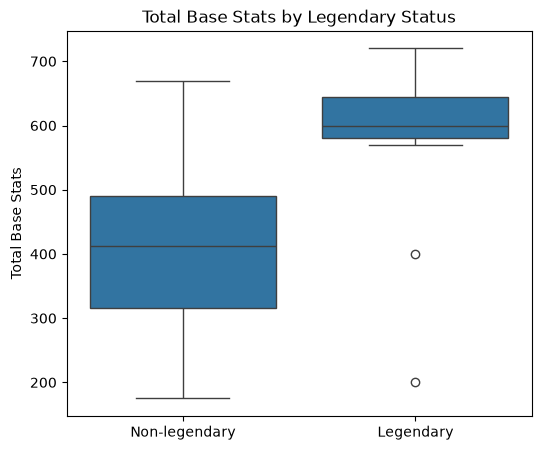

In [49]:
plt.figure(figsize=(6,5))
sns.boxplot(data=df_clean, x='is_legendary', y='base_total')
plt.xticks([0,1], ['Non-legendary', 'Legendary'])
plt.title('Total Base Stats by Legendary Status')
plt.xlabel('')
plt.ylabel('Total Base Stats')
plt.savefig('figures/02_base_total_boxplot.png', dpi = 150, bbox_inches = 'tight')
plt.show()


This plot shows the gap in stats between legendary and non-legendary Pokémon. The legendary median of 600 is far above the non-legendary median of 413, and even the lowest quarter of legendaries (about 580) starts higher than three-quarters of non-legendaries (about 490). The legendary box is narrow, representing the cluster of legendary Pokémon around 600, and there are two legendary outliers: Cosmog (200) and Cosmoem (400), which are the pre-evolved forms of Solgaleo and Lunala (both at 600). The non-legendary distribution is much wider, with its whiskers reaching from below 200 all the way to 670 represented by Slaking. Note that the upper part of the non-legendary box, that is, the pseudo-legendaries and Slaking, span the entire legendary box, which suggests some difficulties for the model in section F.

### D.3 Individual stats by legendary status

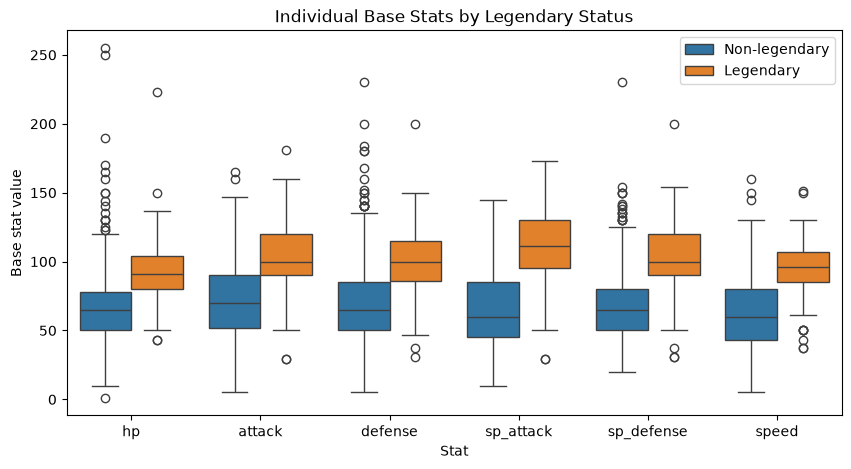

In [50]:
df_clean['status'] = df_clean['is_legendary'].map({0: 'Non-legendary', 1: 'Legendary'}) # readable group names for plot legends

stats_long = df_clean.melt(id_vars = 'status', value_vars = stat_columns,
                           var_name = 'stat', value_name = 'value') # reshapes the data so all stats are under one column

plt.figure(figsize = (10, 5))
sns.boxplot(data = stats_long, x = 'stat', y = 'value', hue = 'status') # draws a boxplot, distinguishing by legendary status
plt.title("Individual Base Stats by Legendary Status")
plt.xlabel("Stat")
plt.ylabel("Base stat value")
plt.legend(title = "") # removes the legend title; seaborn already labels the groups
plt.savefig('figures/03_individual_stats_boxplot.png', dpi = 150, bbox_inches = 'tight') # saves figure in directory
plt.show()

This plot shows the difference in individual base stats between legendary and non-legenday Pokémon. In all stats, the legendary median (roughly 90-110) is above the non-legendary median (roughly 60-70). Special Attack has the most signifcant difference, with the legendary box being the furthest away from the non-legendary box. The legendary special defense and speed boxes also don't touch their non-legendary counter-parts, whereas HP, attack, and defense overlap, or only barely don't touch (in the case of HP). Notice that these individual stats overlap much more than the total seen in the previous plot, and the legendary boxes aren't as narrow, either, indicating that the individual stats don't cluster around particular values as much as the total of the stats does. Laslty, there are many more non-legendary outliers than legendary ones. For one, this is due to the fact that there are more non-legendary Pokémon, but another reason are specialist Pokémon; that is, Pokémon that have one extremely high stat, in return for very low other stats. One prime example is Shuckle, which has a base defense and special defense of 230, but whose other stats are all between 5 and 20. There are also some legendary outliers in both directions, such as Guzzlord with 230 HP, or cosmog with low stats overall, as the base total is only 200.

### D.4 Distribution of total stats for both groups, overlaid

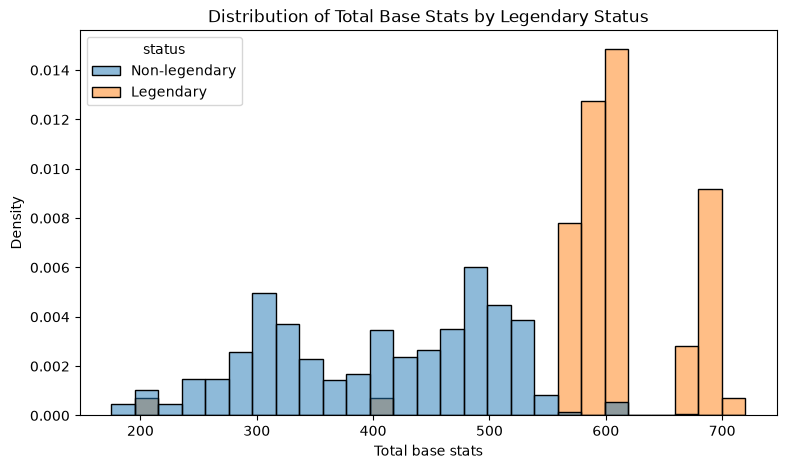

In [51]:
plt.figure(figsize = (9, 5))
sns.histplot(data = df_clean, x = 'base_total', hue = 'status',
             binwidth = 20, stat = 'density', common_norm = False) # histogram for both groups, each scaled to its own size
plt.title("Distribution of Total Base Stats by Legendary Status")
plt.xlabel("Total base stats")
plt.ylabel("Density")
plt.savefig('figures/04_base_total_histogram.png', dpi = 150, bbox_inches = 'tight')
plt.show()

The plot shows the distribution of total base stats by legendary status, and it is important to note that the y-axis shows density, not count. That is, each group is scaled by its own size. Overlaps are colored gray, and the plot shows very well that there is little overlap between the base total of legendary and non-legendary Pokémon. The non-legendary distribution ends roughly after 540, which is where the legendary distribution begins. The legendary Pokémon that are among the non-legendary distribution are Cosmog and Cosmoem, and the non-legendary Pokémon that are overlapping with the legendary distribution are the pseudo-legendaries at 600 and Slaking at 670. 
Overall, one can see two clusters of legendary Pokémon. The first cluster is around 600, which is a common value for legendary Pokémon as well as mythical Pokémon, as noted before: Mythical Pokémon sit at exactly 600, while secondary or 'side-quest' legendaries such as the legendary birds and dogs sit at 580, and the Tapus at 570. However, there is another cluster right around 680-700. This includes the box art legendaries like Ho-Oh, Yveltal, or other Pokémon that are important to the main storyline, such as Mewtwo or Rayquaza. Arceus tops off the histogram at 720, as it is presented as the creator of the Pokémon universe in the games. Between these two clusters, there is a clear gap, with no legendaries having base totals of 620 to 660.
The non-legendary Pokémon have two prominent peaks around 300 and right before 500, which is most likely caused by the different evolution stages of Pokémon, with the later evolution stages having higher stats. These clusters were not visible in the box plots, and offer some new insight into how different kinds of legendaries (box, mythicals, sidequest) get different standard base totals.

### D.5 Percentage of legendary Pokémon per generation

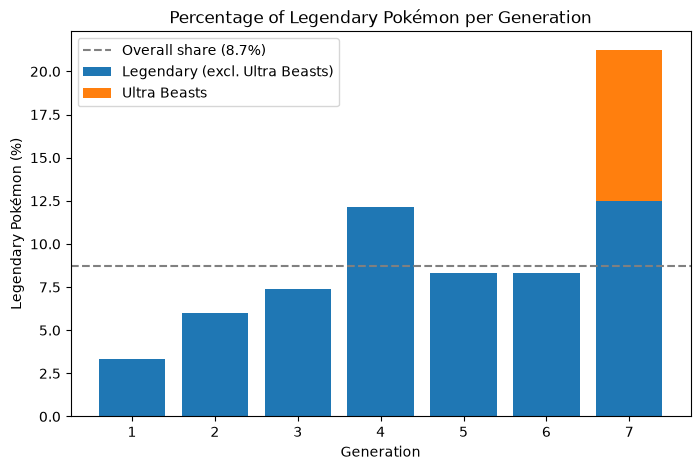

In [52]:
ultra_beasts = ['Nihilego', 'Buzzwole', 'Pheromosa', 'Xurkitree',
                'Celesteela', 'Kartana', 'Guzzlord'] # creating a list of all ultra beasts
is_ultra_beast = df_clean['name'].isin(ultra_beasts)
is_other_legendary = (df_clean['is_legendary'] == 1) & ~is_ultra_beast # considering only 'standard' legendary Pokémon

# % of each generation that is an Ultra Beast / another legendary
ub_share = is_ultra_beast.groupby(df_clean['generation']).mean() * 100
other_share = is_other_legendary.groupby(df_clean['generation']).mean() * 100

plt.figure(figsize = (8, 5))
plt.bar(other_share.index, other_share.values, label = 'Legendary (excl. Ultra Beasts)')
plt.bar(ub_share.index, ub_share.values, bottom = other_share.values,
        label = 'Ultra Beasts') # stacked on top of the other legendaries
plt.axhline(df_clean['is_legendary'].mean() * 100, color = 'gray', linestyle = '--',
            label = 'Overall share (8.7%)') # drawing a reference line for the overall share
plt.title("Percentage of Legendary Pokémon per Generation")
plt.xlabel("Generation")
plt.ylabel("Legendary Pokémon (%)")
plt.legend()
plt.savefig('figures/05_legendary_share_by_generation.png', dpi = 150, bbox_inches = 'tight')
plt.show()

This plot shows the share of legendary Pokémon in each Generation, with ultra beasts as a separate segment, and a dashed line marking the overall share (8.7%). The percentage rises unevenly for 3% to 6% in Generation 2, 7% in Generation 3, and about 8% in Generation 5 and 6. Generation 4 and 7 are the clear outliers, and the only Generations with an above average share of legendary Pokémon. Generation 4's peak of 12% is explained by the two legendary trios and the four mythical Pokémon, as Generation 4 revolved a lot around mythology. Generation 7 has by far the highest peak with 21.25%, which is heavily skewed by the 7 Ultra Beasts that were introduced as a new category of Pokémon, rather than as standard legendary Pokémon. Without these Ultra Beasts, Generation is roughly on the same level as Generation 4 at about 12.5%. Apart from the Ultra Beasts, Generation 7 also introduced the four Tapus, and the evolution chain of Cosmog and Cosmoem, so both the peak in Generation 4 as well as Generation 7 stems from introducing multiple groups of legendary Pokémon, rather than individual legendaries. 
It's important to note, however, that because every generation only has 72-107 new Pokémon, a single legendary Pokémon can noticeably shift the share. Section E will investigate whether this pattern is actually significant.

### D.6 Type differences between legendary and non-legendary Pokémon

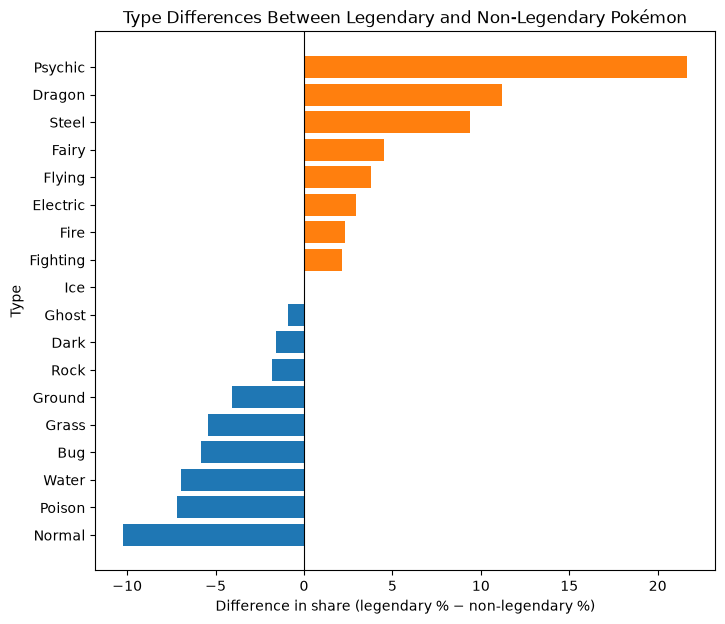

In [53]:
type_diff = type_shares['difference'].sort_values() # sorted, so the largest differences end up at the top
type_names = type_diff.index.str.replace('type_', '').str.capitalize() # removes the 'type_'-prefix: 'type_psychic' -> 'Psychic'
bar_colors = ['tab:orange' if d > 0 else 'tab:blue' for d in type_diff] # orange: more common among legendaries

plt.figure(figsize = (8, 7))
plt.barh(type_names, type_diff.values, color = bar_colors) # one horizontal bar per type
plt.axvline(0, color = 'black', linewidth = 0.8) # zero line: no difference between the groups
plt.title("Type Differences Between Legendary and Non-Legendary Pokémon")
plt.xlabel("Difference in share (legendary % − non-legendary %)")
plt.ylabel("Type")
plt.savefig('figures/06_type_differences.png', dpi = 150, bbox_inches = 'tight')
plt.show()

For each type, this plot shows the difference between its share among legendaries and among non-legendaries. Here, orange bars mean overrepresented among legendaries, while blue means underrepresented. Most notably, Psychic is by far the most overrepresented type with a difference of +22 percentage points, which likely reflects, as described earlier, that legendary Pokémon are designed to be 'mysterious', which is exactly what the Psychic type represents. Psychic is followed by Dragon and Steel with about +11 and +9, respectively. Both of these types represent powerful Pokémon and are relatively rare among non-legendaries, so it makes sense that they are overrepresented among legendaries.
In the middle field, Ice has no visible bar, which means that its share is almost identical in both groups. Lastly, Normal marks the end of the list at about -10, followed by Poison and Water at about -8. Normal is not only common among non-legendaries, but also rare among legendaries, so both effects add up. Poison is even rarer among legendaries, with only one legendary Pokémon being type Poison. Water is more surprising, but can be explained by the large share of non-legendary Water Pokémon, so even if legendary Water Pokémon aren't rare, their large share among non-legendaries outweighs the legendary share.
In general, the most overrepresented types among legendaries are those that are rare among non-legendaries. Legendary Pokémon seemingly tend to, by design, get rarer types.
One thing to be aware of: since there are only 70 legendary Pokémon, a single legendary Pokémon shifts a share by 1.4%, so differences of a few percentage points mean only a few Pokémon.

### D.7 Correlation heatmap of different attributes

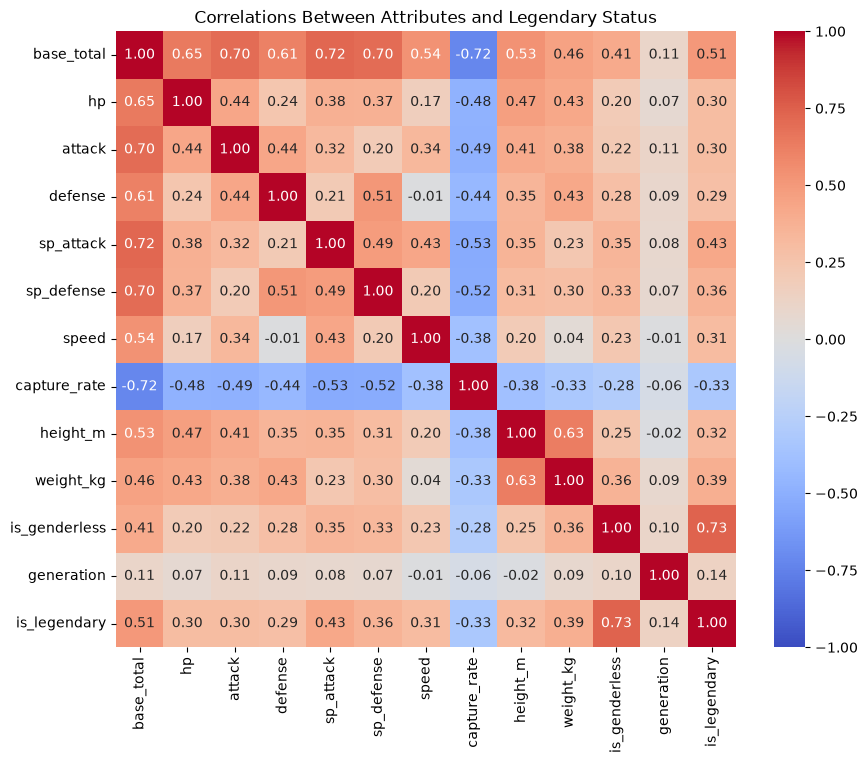

In [54]:
corr_matrix = df_clean[attributes + ['is_legendary']].corr() # correlations between all pairs of attributes

plt.figure(figsize = (10, 8))
sns.heatmap(corr_matrix, annot = True, fmt = '.2f', cmap = 'coolwarm',
            vmin = -1, vmax = 1, center = 0) # colored grid, with each correlation written in its cell
plt.title("Correlations Between Attributes and Legendary Status")
plt.savefig('figures/07_correlation_heatmap.png', dpi = 150, bbox_inches = 'tight')
plt.show()

In [55]:
# checking if the correlation between genderlessness and the base total is due to legendary Pokémon
non_legendary = df_clean[df_clean['is_legendary'] == 0]
print(non_legendary['is_genderless'].corr(non_legendary['base_total']))

0.07005408495768205


In [56]:
# checking correlation between speed and defense without the boost from total stats
defense_share = df_clean['defense'] / df_clean['base_total']
speed_share = df_clean['speed'] / df_clean['base_total']
print(defense_share.corr(speed_share))

-0.4957426993739753


The plot shows the correlations between different attributes and legendary status, represented as a correlation heatmap. The lowest row repeats the ranking in C.7, where being genderless is clearly the strongest association (0.73), followed by base_total (0.51) and sp_attack (0.43). Generation has the weakest association, and this is true for most attributes: the generation stays, apart from is_legendary, between 0.11 and essentially zero. 
The strongest other relationship between two different attributes lies between capture_rate and base_total at -0.72. This means that stronger Pokémon are systematically harder to catch, whether legendary or not. This actually explains why the capture_rate isn't as strongly associated with being legendary as initially expected: it doesn't track legendary Pokémon, but is low for strong non-legendaries in general, such as the pseudo-legendaries.
Another unsurprising result: base_total correlates strongly with each individual stat (0.54 - 0.72). This makes sense, since a higher total means that there are more stat points to distribute among the individual stats to begin with. For section F, this means that base_total and the six stats carry overlapping information, so there is no need to use all of them as features.
On the other hand, being genderless does not correlate as strongly with the individual stats (0.20 - 0.35). However, there is a moderate correlation between genderlessness and the base total at 0.41. Checking the correlation between genderlessness and the base total among non-legendaries drops this number to essentially zero (0.07), so the moderate correlation before most likely just came from genderlessness being highly correlated with legendary status. This gives us a great feature to combine with base_total for our prediction model, since there is little overlapping information between these two.
Another strong correlation is between height and weight at 0.63. This makes sense, because bigger Pokémon tend to be heavier and vice-versa, though it is not a perfect correlation, so there are still small but dense Pokémon (consider Cosmoem's 999kg at only 0.1m as an extreme example), or big but relatively light Pokémon (such as Wailord weighing less than 400kg despite its 14.5m).  

### Summary of Section D

**What each plot showed**
1. **Counts:** There are 70 legendary vs 731 non-legendary Pokémon, and the plot shows the imbalance clearly; legendaries only make up about 8.7% of all Pokémon.
2. **Total stats box plot:** For the total stats, the middle halves are clearly separated. Cosmog and Cosmoem are the only legendary outliers. The non-legendary whisker extends into the range of legendary stats with the pseudo-legendaries at 600 and Slaking's 670.
3. **Individual stats box plot:** Legendaries have higher points in every stat, although special attack and special defense separate best. Individual stats overlap more than the total, however.
4. **Histogram:** There are two different clusters of legendary Pokémon: one around 570-620, and another around 670-720, with a clear gap between. The weaker cluster includes mythical Pokémon and secondary legendary Pokémon, whereas the other cluster represents the box art, main story legendaries. The pseudo-legendaries share the 600 bin, and are the most noticeable overlap.
5. **Generations:** There is an uneven rise from Generation 1's 3% to 6% in Generation 2, 7% in Generation 3, and 8% in Generation 5 and 6. Generation 4 and 7 peak at 12% and 21.25%, respectively. 8.75 percentage points of Generation 7's share come from Ultra Beasts; without them Generation 7 is roughly even with Generation 4.
6. **Types:** Psychic is by far the most over-represented type among legendaries, followed by Dragon and Steel. Normal, Poison, and Water are the most under-represented. In general, legendaries tend to get rare types more often.
7. **Heatmap:** For legendary status, genderlessness has the strongest association (0.73). The capture rate doesn't exactly track legendary status, but power in general, i.e. base_total (-0.72). Genderlessness and total stats carry separate information, so they are a good combination of features for prediction models.

**Main takeaways**
The histogram's clusters and the generation 7 jump show that legendary status really encompasses different categories of Pokémon: secondary legendaries, mythicals, box art legendaries, and Ultra Beasts.
There is little overlap between legendaries and non-legendaries in stats, but where they do overlap (most notably pseudo-legendaries, Slaking, and Cosmog and Cosmoem), stats alone can't separate them.
For section F, using both base_total and the six individual stats is redundant, so we can choose either one. Genderlessness adds information the stats don't, so this makes a good additional feature. Either way, we can expect some errors at the 600 overlap.